# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ssarimm/Machine-Learning-Internship---Flyrank/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### Purpose of the ranked action queue

The queue prioritizes content pages for human review using transparent, rule-based signals rather than treating the current model as a reliable predictor. Pages receive higher priority when they have an observed declining trend, have not been updated recently, and have meaningful search demand.

The queue is a decision-support tool. A high score means that a page meets more of the defined review criteria; it does not mean that a refresh will improve performance or that the page will continue to decline.

Each recommendation includes reason codes so that a reviewer can understand why the page was prioritized. The ranking is intended for a small, non-production pilot and does not automatically edit, delete, or publish content.


In [3]:

print("Dataset shape:", df.shape)

print("\nAll column names:")
for col in df.columns:
    print(repr(col))


Dataset shape: (30000, 53)

All column names:
'content_id'
'client_id'
'search_volume'
'competition'
'competition_level'
'cpc'
'content_type'
'main_intent'
'word_count'
'char_count'
'provider_used'
'model_used'
'impressions_90d'
'clicks_90d'
'pageviews_90d'
'sessions_90d'
'users_90d'
'engaged_sessions_90d'
'ai_sessions_90d'
'scroll_events_90d'
'days_with_impressions'
'days_with_sessions'
'impressions_last_30d'
'clicks_last_30d'
'sessions_last_30d'
'impressions_prev_30d'
'clicks_prev_30d'
'sessions_prev_30d'
'content_age_days'
'age_tier'
'age_tier_order'
'days_since_last_update'
'freshness_tier'
'word_count_tier'
'char_count_tier'
'ctr'
'avg_position'
'engagement_rate'
'scroll_rate'
'ai_traffic_pct'
'impression_tier'
'position_tier'
'trend_direction'
'trend_pct'
'health_score'
'needs_indexing'
'is_quick_win'
'needs_ctr_fix'
'needs_engagement_fix'
'ai_opportunity'
'is_underperformer'
'is_declining'
'is_initial_refresh_candidate'


In [4]:

import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv("/content/content_refresh_anonymized.csv")

# Validate the columns we actually need
required_columns = [
    "content_id",
    "trend_direction",
    "days_since_last_update",
    "search_volume"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

playbook_df = df.copy()

# Rule 1: stale content (180+ days since last update)
playbook_df["days_since_last_update"] = pd.to_numeric(
    playbook_df["days_since_last_update"], errors="coerce"
)
playbook_df["is_stale"] = (
    playbook_df["days_since_last_update"] >= 180
)

# Rule 2: meaningful search demand
playbook_df["search_volume"] = pd.to_numeric(
    playbook_df["search_volume"], errors="coerce"
)

positive_volume = playbook_df.loc[
    playbook_df["search_volume"] > 0, "search_volume"
]
if positive_volume.empty:
    raise ValueError("No positive search_volume values found.")

demand_threshold = positive_volume.median()

playbook_df["has_meaningful_demand"] = (
    (playbook_df["search_volume"] > 0)
    & (playbook_df["search_volume"] >= demand_threshold)
)

# Rule 3: historical observed decline, not a future prediction
playbook_df["observed_decline"] = (
    playbook_df["trend_direction"].eq("down")
)

# Explainable reason codes
def get_reason_codes(row):
    reasons = []
    if row["observed_decline"]:
        reasons.append("OBSERVED_DECLINE")
    if row["is_stale"]:
        reasons.append("STALE_180D_PLUS")
    if row["has_meaningful_demand"]:
        reasons.append("MEANINGFUL_SEARCH_DEMAND")
    return reasons

playbook_df["reason_codes"] = playbook_df.apply(
    get_reason_codes, axis=1
)

# Rule-based priority score; NOT a probability
playbook_df["priority_score"] = (
    playbook_df["observed_decline"].astype(int) * 3
    + playbook_df["is_stale"].astype(int) * 2
    + playbook_df["has_meaningful_demand"].astype(int)
)

# Human-review action mapping
def recommend_action(row):
    decline = row["observed_decline"]
    stale = row["is_stale"]
    demand = row["has_meaningful_demand"]

    if decline and stale and demand:
        return "Review refresh opportunity; verify intent and content gaps"
    elif decline and stale:
        return "Diagnose decline and check whether content is outdated"
    elif decline and demand:
        return "Audit search intent, content gaps, and technical issues"
    elif decline:
        return "Investigate observed decline before choosing an action"
    elif stale and demand:
        return "Review freshness and accuracy; refresh only if justified"
    elif stale:
        return "Check whether content is outdated"
    else:
        return "Monitor performance and assess content usefulness"

playbook_df["recommended_action"] = playbook_df.apply(
    recommend_action, axis=1
)

# Keep pages with at least one priority signal
queue = playbook_df.loc[
    playbook_df["priority_score"] > 0
].copy()

queue = queue.sort_values(
    ["priority_score", "search_volume"],
    ascending=[False, False],
    na_position="last"
)

# Export only necessary, anonymized fields
queue = queue[
    [
        "content_id",
        "priority_score",
        "reason_codes",
        "recommended_action",
        "trend_direction",
        "days_since_last_update",
        "search_volume"
    ]
].reset_index(drop=True)

queue.insert(0, "queue_rank", range(1, len(queue) + 1))

print("Dataset rows:", len(df))
print("Positive search-volume median:", demand_threshold)
print("Pages in review queue:", len(queue))
print("\nTop 10 recommended actions:")
display(queue.head(10))


Dataset rows: 30000
Positive search-volume median: 20.0
Pages in review queue: 20825

Top 10 recommended actions:


,queue_rank,content_id,priority_score,reason_codes,recommended_action,trend_direction,days_since_last_update,search_volume
0,1,content_bbca724138f2,6,"[OBSERVED_DECLINE, STALE_180D_PLUS, MEANINGFUL...",Review refresh opportunity; verify intent and ...,down,236,1600.0
1,2,content_24abafed9707,6,"[OBSERVED_DECLINE, STALE_180D_PLUS, MEANINGFUL...",Review refresh opportunity; verify intent and ...,down,231,480.0
2,3,content_02b0d6e30129,6,"[OBSERVED_DECLINE, STALE_180D_PLUS, MEANINGFUL...",Review refresh opportunity; verify intent and ...,down,313,110.0
3,4,content_7a888d3d99c8,6,"[OBSERVED_DECLINE, STALE_180D_PLUS, MEANINGFUL...",Review refresh opportunity; verify intent and ...,down,313,90.0
4,5,content_f4b3081037b3,6,"[OBSERVED_DECLINE, STALE_180D_PLUS, MEANINGFUL...",Review refresh opportunity; verify intent and ...,down,231,90.0
5,6,content_4f241bad48a3,5,"[OBSERVED_DECLINE, STALE_180D_PLUS]",Diagnose decline and check whether content is ...,down,236,10.0
6,7,content_149c671a2a91,5,"[OBSERVED_DECLINE, STALE_180D_PLUS]",Diagnose decline and check whether content is ...,down,235,10.0
7,8,content_129753e3095f,5,"[OBSERVED_DECLINE, STALE_180D_PLUS]",Diagnose decline and check whether content is ...,down,305,10.0
8,9,content_94991fe6268c,5,"[OBSERVED_DECLINE, STALE_180D_PLUS]",Diagnose decline and check whether content is ...,down,313,10.0
9,10,content_ab18b5811c02,5,"[OBSERVED_DECLINE, STALE_180D_PLUS]",Diagnose decline and check whether content is ...,down,305,10.0


### Ranked queue results

The rule-based queue contains 20,825 pages out of 30,000 dataset rows. The median positive search-volume threshold is 20.0.

The highest-priority pages score 6 because they meet all three criteria: observed decline, at least 180 days since the last update, and meaningful search demand. Pages with a score of 5 meet the decline and staleness criteria but do not meet the demand threshold.

The queue provides reason codes and suggested review actions to make prioritization transparent. The large queue size means that a reviewer should begin with the highest-ranked pages and verify their search intent, content accuracy, technical health, and business value before approving any changes.

The ranking is based on rules applied to the available dataset. It does not establish that a content refresh will recover traffic or that the observed decline will continue.


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

### Intended use

The playbook is intended for SEO analysts and content editors conducting a small, non-production content-review pilot. It organizes pages into a review queue using observed trend direction, content staleness, and search-demand signals.

A reviewer can use the queue to decide which pages to investigate first, then examine search intent, factual accuracy, competing pages, technical indexing issues, internal links, and business relevance before recommending an action.

### Limits

- The priority score is a rule-based score, not a probability of future decline or successful recovery.
- The observed `trend_direction` describes the available historical data; it does not predict the next period.
- Staleness and search demand alone do not prove that content is outdated or worth refreshing.
- The queue does not estimate the causal impact of a refresh.
- The Week 6 reduced-feature model showed limited ranking performance, so this playbook does not rely on its output as a reliable predictive signal.
- The current dataset does not establish that every feature was available before the target period.
- The rules have not been validated through a controlled refresh experiment or a genuinely future-period evaluation.
- The queue must not automatically publish, rewrite, delete, or change pages.

This is a prioritization aid for human judgment, not a production decision engine.


In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### Human review requirements

Every page in the action queue must be reviewed by an SEO analyst or content editor before any change is approved. The priority score determines review order only; it does not guarantee that a page needs updating.

Before recommending an action, the reviewer should:

1. **Verify the signal:** Check the page's historical impressions, trend direction, and last-update date. Confirm that the observed decline is meaningful and not simply a short-term fluctuation or a data-quality issue.
2. **Check search intent:** Confirm that the page still matches the queries and needs of its intended audience.
3. **Review content quality:** Check factual accuracy, outdated information, completeness, readability, and whether the page has meaningful content gaps.
4. **Check technical factors:** Investigate indexing, canonical tags, redirects, internal links, and other technical issues that could explain the observed performance.
5. **Assess business value:** Consider the page's strategic importance, conversion value, maintenance cost, and whether a refresh is worth the effort.
6. **Record the decision:** Mark the page as refresh, investigate further, monitor, or no action. Record the reason for the decision and the reviewer responsible.

### No-go list: actions that must not be automated

The playbook must not independently:

- Rewrite, publish, or modify live content.
- Delete pages, remove URLs, or change redirects or canonical tags.
- Make factual, legal, medical, financial, or other high-impact claims without qualified human verification.
- Assume that an old page is outdated solely because of its age.
- Assume that declining impressions were caused by content quality or that a refresh will recover traffic.
- Automatically prioritize pages for deletion or major investment based only on the rule-based score.
- Treat missing, incomplete, or unreliable data as evidence that a page is underperforming.

### Human approval and safeguards

All recommended changes require human approval before implementation. High-impact changes, technically complex fixes, and pages with significant business value should receive additional review from the relevant subject-matter expert or technical owner.

The reviewer should document the original signal, the decision, the reason, and any subsequent performance observations. This creates an auditable record and allows the team to evaluate whether the playbook is useful over time.

The playbook is a decision-support tool. Final actions remain the responsibility of the human reviewer.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

### Monitoring plan

The playbook should be reviewed monthly during the initial pilot. Monitoring is intended to identify data-quality problems, unusual changes in the queue, and whether the recommendations are useful to human reviewers.

#### 1. Data-quality monitoring

Before generating each queue, check:

- Required columns are present and have the expected data types.
- Missing values in important fields, including `trend_direction`, `days_since_last_update`, and `search_volume`.
- Duplicate content identifiers.
- Whether the reporting period and trend labels are consistent with the intended analysis period.

**Trigger:** If required columns are missing, duplicate identifiers are unexpectedly common, or important fields have substantial missingness, investigate the issue before using the queue. Do not silently treat missing values as evidence of poor performance.

#### 2. Queue and trend monitoring

Track the following metrics for each run:

- Total number of pages in the queue.
- Percentage of dataset pages included in the queue.
- Number and percentage of pages with an observed declining trend.
- Number of pages in each priority-score tier.
- Number of pages meeting each reason-code criterion.

**Provisional trigger:** Investigate if the queue size changes by more than 25% relative to the previous comparable run, or if the observed decline rate changes by more than 10 percentage points. These are proposed operational thresholds for the pilot, not statistically validated limits.

Changes may reflect genuine performance shifts, different reporting periods, data changes, or bugs in the pipeline. Investigate before changing the rules.

#### 3. Human-review usefulness

Record reviewer outcomes for a sample of prioritized pages. Track:

- Number of pages reviewed.
- Percentage judged to need a refresh.
- Percentage requiring technical investigation.
- Percentage assigned to monitoring or no action.
- Reasons reviewers disagree with the recommended action.
- Review time per page, where practical.

Review the highest-ranked pages first and compare recommendations with reviewer decisions. If many reviewed pages do not justify action, inspect the rules and reason codes before expanding the pilot.

#### 4. Retraining and rule-change triggers

Do not retrain a model simply because a month has passed. Consider model redevelopment only when:

- New, timestamped data is available for a meaningful future evaluation period.
- Outcome labels are available after the recommendations or interventions being evaluated.
- Data quality and feature availability have been checked.
- Evaluation can use a time-based split that reflects the intended future use.
- Performance is compared with a simple baseline and the current rule-based playbook.

If the rules repeatedly produce low-value recommendations, first review the thresholds, definitions, and reviewer feedback. Any revised rules should be documented and evaluated before replacing the existing version.

The Week 6 model's limited ranking performance is not sufficient evidence to deploy it or assume that retraining will improve results.

### Monitoring limitations

The thresholds above are initial operational safeguards, not validated statistical control limits. Monthly monitoring can identify changes and prompt investigation, but it cannot establish that the playbook causes better content performance. Any claim about the effect of content refreshes would require appropriate follow-up measurement and a suitable evaluation design.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

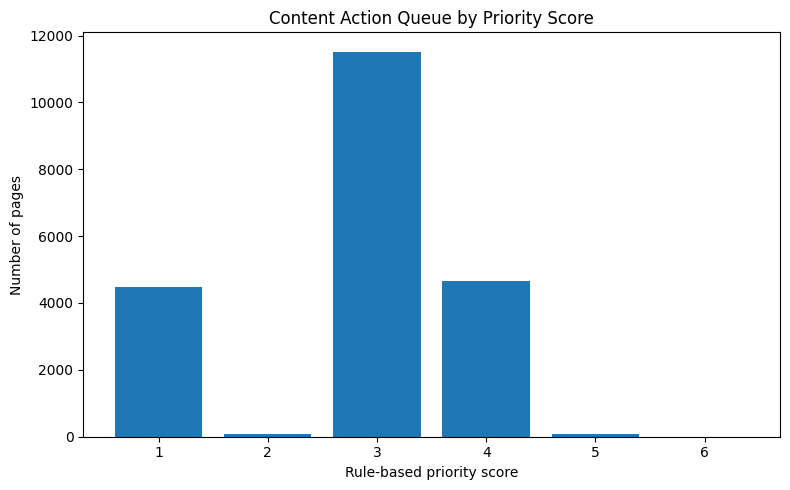

Export complete:
Queue CSV: work/outputs/content_action_queue.csv (20,825 rows)
Figure:    work/figures/w07_priority_score_distribution.png
Metrics:   work/metrics/w07_action_playbook_metrics.json
Queue share: 69.42%


In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# Create folders for the deliverables
OUTPUT_DIR = Path("work/outputs")
FIGURES_DIR = Path("work/figures")
METRICS_DIR = Path("work/metrics")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Copy the queue from Section 1 so we do not modify the original
queue_export = queue.copy()

# Recalculate the thresholds from the dataset
search_volume = pd.to_numeric(df["search_volume"], errors="coerce")
positive_search_volume = search_volume[search_volume > 0]
demand_threshold = float(positive_search_volume.median()) if len(positive_search_volume) else None
stale_threshold = 180

# Add explicit archetypes so the queue is easier to interpret
def classify_archetype(row):
    decline = str(row["trend_direction"]).lower() == "down"
    days_stale = pd.to_numeric(
        pd.Series([row["days_since_last_update"]]), errors="coerce"
    ).iloc[0]
    volume = pd.to_numeric(
        pd.Series([row["search_volume"]]), errors="coerce"
    ).iloc[0]

    stale = pd.notna(days_stale) and days_stale >= stale_threshold
    demand = (
        demand_threshold is not None
        and pd.notna(volume)
        and volume >= demand_threshold
    )

    if decline and stale and demand:
        return "DECLINING_STALE_DEMAND"
    if decline and stale:
        return "DECLINING_STALE_LOW_DEMAND"
    if decline and demand:
        return "DECLINING_WITH_DEMAND"
    if decline:
        return "DECLINING_OTHER"
    if stale and demand:
        return "STALE_WITH_DEMAND"
    if stale:
        return "STALE_OTHER"
    if demand:
        return "DEMAND_ONLY"
    return "OTHER_REVIEW_SIGNAL"

queue_export["action_archetype"] = queue_export.apply(
    classify_archetype, axis=1
)

# Put the most useful review fields first
preferred_columns = [
    "queue_rank",
    "content_id",
    "priority_score",
    "action_archetype",
    "reason_codes",
    "recommended_action",
    "trend_direction",
    "days_since_last_update",
    "search_volume",
]
export_columns = [
    col for col in preferred_columns if col in queue_export.columns
]
queue_export = queue_export[export_columns]

# Export the ranked queue CSV.
# Per the assignment, this file should remain out of Git.
queue_path = OUTPUT_DIR / "content_action_queue.csv"
queue_export.to_csv(queue_path, index=False)

# Create a reproducible priority-score distribution figure
fig, ax = plt.subplots(figsize=(8, 5))

if not queue_export.empty:
    score_counts = (
        queue_export["priority_score"]
        .value_counts()
        .sort_index()
    )
    ax.bar(score_counts.index.astype(str), score_counts.values)
    ax.set_xlabel("Rule-based priority score")
    ax.set_ylabel("Number of pages")
    ax.set_title("Content Action Queue by Priority Score")
else:
    ax.text(0.5, 0.5, "No pages in queue", ha="center", va="center")
    ax.set_axis_off()

fig.tight_layout()
figure_path = FIGURES_DIR / "w07_priority_score_distribution.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Metrics JSON: keep this file tracked in Git
metrics = {
    "dataset_rows": int(len(df)),
    "queue_rows": int(len(queue_export)),
    "queue_percentage": round(
        100 * len(queue_export) / len(df), 2
    ) if len(df) else None,
    "stale_days_threshold": stale_threshold,
    "positive_search_volume_median_threshold": demand_threshold,
    "priority_score_definition": {
        "observed_decline": 3,
        "stale_180_days_or_more": 2,
        "meaningful_search_demand": 1,
        "interpretation": (
            "Rule-based prioritization score; not a probability "
            "of decline or successful recovery."
        ),
    },
    "action_archetype_counts": {
        str(key): int(value)
        for key, value in queue_export["action_archetype"]
        .value_counts()
        .items()
    },
    "week_6_reduced_feature_model": {
        "decision_tree_roc_auc": 0.508,
        "decision_tree_average_precision": 0.510,
        "baseline_roc_auc": 0.486,
        "baseline_average_precision": 0.504,
        "interpretation": (
            "Limited ranking performance; not treated as a reliable "
            "predictive signal."
        ),
    },
    "limitations": [
        "Observed historical trends are not forecasts.",
        "The score does not estimate the causal effect of a content refresh.",
        "Human review is required before action.",
        "Temporal safety of all features has not been established."
    ],
}

metrics_path = METRICS_DIR / "w07_action_playbook_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Export complete:")
print(f"Queue CSV: {queue_path} ({len(queue_export):,} rows)")
print(f"Figure:    {figure_path}")
print(f"Metrics:   {metrics_path}")
print(f"Queue share: {metrics['queue_percentage']}%")



## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.